<div style="background:#F5EDF4; border-top:3px solid #A83296; padding:15px; border-radius:0 0 8px 8px">
<h1 style="color:#493347; margin:0">Lab — Tools & MCP (Module 4)</h1>
<p style="color:#655263; margin:4px 0 0 0">Intro to Generative AI / Agentic AI — University of Petra</p>
</div>

**Course:** 307307 BI Methods for Generative AI (Agentic AI half)  
**Reference:** Grootendorst &amp; Alammar, *An Illustrated Guide to AI Agents* (O'Reilly, 2026), Chapter 5.

Our agent can think (M2) and remember (M3) — but it still cannot *do* anything. Today we give it **tools**, so it can act. You will watch it emit a tool call, we execute the tool, and it uses the result to answer.

**This is a run-and-observe lab.** Run each cell and read the output; there is one small exercise at the end.

<div align="center">
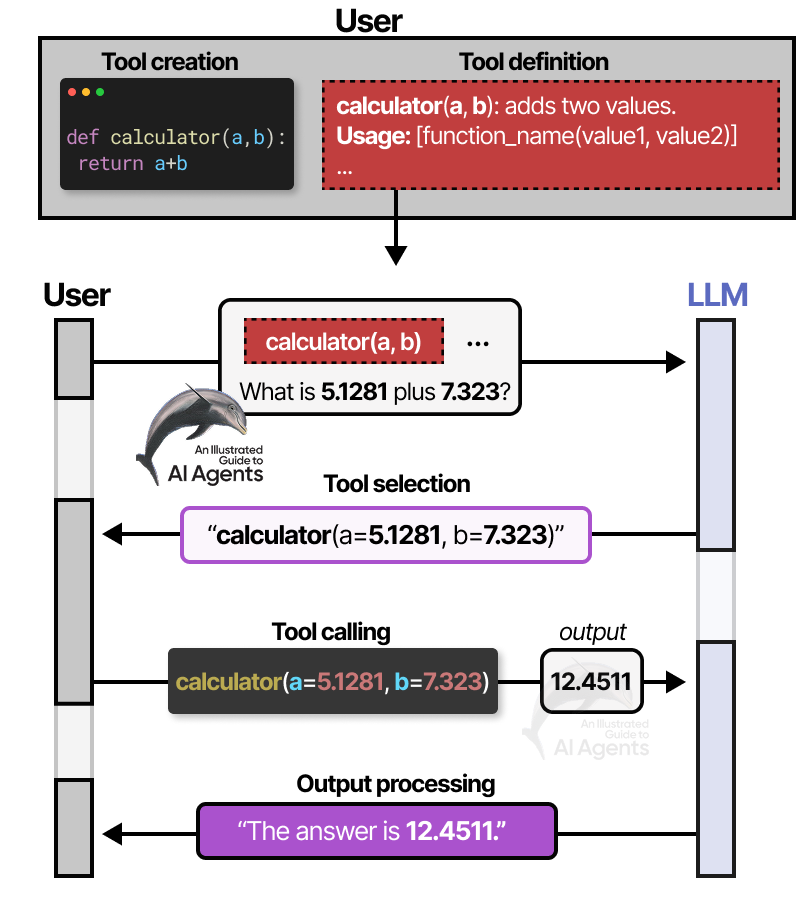
<br><span style="color:#6E6E6E; font-size:90%"><i>The tool-calling flow: create, define, select, call, process output (Figure 5-5). An Illustrated Guide to AI Agents (O'Reilly, 2026)</i></span>
</div>

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Part 0 — Setup (just run these)</h2>
</div>

Re-creates the `LLM` brain from Module 2 so the notebook runs on its own.

In [ ]:
# In Google Colab, remove the leading # to install. Locally, run once.
# %pip install -q openai

In [ ]:
import os, json, re
from getpass import getpass
from dataclasses import dataclass
from openai import OpenAI

if not os.environ.get('GEMINI_API_KEY'):
    os.environ['GEMINI_API_KEY'] = getpass('Paste your Gemini API key (hidden): ')

MODEL = 'gemini-3.8-flash'   # a model enabled on your account
BASE_URL = 'https://generativelanguage.googleapis.com/v1beta/openai/'

@dataclass
class Response:
    content: str = ''
    tool_call: dict | None = None

class LLM:
    def __init__(self, model=MODEL):
        self.client = OpenAI(api_key=os.environ['GEMINI_API_KEY'], base_url=BASE_URL)
        self.model = model
    def generate(self, messages):
        r = self.client.chat.completions.create(model=self.model, messages=messages, temperature=0.0)
        return Response(content=r.choices[0].message.content or '')

llm = LLM()
print('Ready. Model:', MODEL)

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Part 1 — Create the tools</h2>
</div>

A tool is just a Python function. We make two: a calculator and a (pretend) weather lookup. Note the LLM only ever sees text, so numbers arrive as strings.

In [ ]:
import random

def multiply(a: str, b: str) -> str:
    """Multiply two numbers."""
    return str(float(a) * float(b))

def get_weather(location: str) -> str:
    """Get the current weather for a location."""
    status = random.choice(['Sunny', 'Cloudy', 'Rainy'])
    return f'{status}, {random.randint(10, 30)} degrees in {location}'

print(multiply('5.1', '7.3'))
print(get_weather('Amman'))

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Part 2 — Define the tools to the LLM</h2>
</div>

We tell the model which tools exist and the exact format to reply in. This is **prompted** tool calling: the tools live in the system prompt, and a small **parser** reads the model's JSON reply.

In [ ]:
class Tools:
    """A tiny tool registry: describe tools to the LLM and run them."""
    def __init__(self):
        self.registry = {}
    def add(self, func, description):
        self.registry[func.__name__] = {'func': func, 'description': description}
    def prompt(self):
        lines = [f'- {n}: {t["description"]}' for n, t in self.registry.items()]
        tools_list = chr(10).join(lines)
        return (
            'You can use these tools:\n' + tools_list + '\n\n'
            'When a tool is needed, reply with ONLY a JSON object like:\n'
            '{"tool": "multiply", "kwargs": {"a": "5.1", "b": "7.3"}}\n'
            'If no tool is needed, just answer normally.'
        )
    def parse(self, text):
        # Find a JSON object that mentions a tool (tolerate code fences / extra text).
        m = re.search(r'\{.*\"tool\".*\}', text, re.DOTALL)
        if not m:
            return None
        try:
            return json.loads(m.group(0))
        except json.JSONDecodeError:
            return None
    def execute(self, call):
        name, kwargs = call['tool'], call.get('kwargs', {})
        if name not in self.registry:
            return f"Tool '{name}' not found."
        return self.registry[name]['func'](**kwargs)

tools = Tools()
tools.add(multiply, 'Multiply two numbers: multiply(a, b)')
tools.add(get_weather, 'Get the weather: get_weather(location)')
print(tools.prompt())

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Part 3 — The agent calls a tool</h2>
</div>

The agent now: sends the question (with the tools in the system prompt) → if the reply is a **tool call**, we **execute** it and feed the result back as an **OBSERVATION** → the model gives a final answer. Watch the intent, then the action, then the answer.

In [ ]:
class TinyAgent:
    def __init__(self, llm, tools):
        self.llm = llm
        self.tools = tools

    def run(self, task, verbose=True):
        messages = [
            {'role': 'system', 'content': 'You are a helpful assistant.\n\n' + self.tools.prompt()},
            {'role': 'user', 'content': task},
        ]
        reply = self.llm.generate(messages).content          # THOUGHT
        call = self.tools.parse(reply)
        if call is None:
            return reply                                       # no tool needed
        if verbose: print('  ACTION (intent):', call)
        result = self.tools.execute(call)                      # we run it
        if verbose: print('  OBSERVATION (result):', result)
        messages.append({'role': 'assistant', 'content': reply})
        messages.append({'role': 'user', 'content': f'OBSERVATION: {result}'})
        return self.llm.generate(messages).content             # ANSWER

agent = TinyAgent(llm, tools)
print('Q: What is 5.1 times 7.3?')
print('A:', agent.run('What is 5.1 times 7.3?'))

The model did **not** do the multiplication itself — it asked for the `multiply` tool, *we* ran it, and it used the result. Now try a question that needs no tool, and one that needs the weather tool:

In [ ]:
print('A:', agent.run('Say hello in one short sentence.'))   # no tool call
print()
print('Q: What is the weather in Amman?')
print('A:', agent.run('What is the weather in Amman?'))        # uses get_weather

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Exercise</h2>
</div>

**Task A.** Add a new tool `word_count(text)` that returns the number of words in a string. Register it, then ask the agent: *"How many words are in: the quick brown fox jumps"*.

**Task B (think, no code).** In a comment, explain why it is safer that *our code* runs the tool instead of the LLM running it directly.

Fill in the `# YOUR CODE HERE` lines, then check the solution below.

In [ ]:
# YOUR CODE HERE
# Task A: define word_count, register it, and ask the agent.
# def word_count(text: str) -> str:
#     ...
# tools.add(word_count, 'Count the words in a string: word_count(text)')
# print(agent.run('How many words are in: the quick brown fox jumps'))

# Task B (answer in a comment): why is it safer that our code runs the tool?
# Answer: ...

**Solution** (try it yourself first):

In [ ]:
# --- Solution ---
# Task A
def word_count(text: str) -> str:
    """Count the words in a string."""
    return str(len(text.split()))

tools.add(word_count, 'Count the words in a string: word_count(text)')
print(agent.run('How many words are in: the quick brown fox jumps'))

# Task B
# The LLM only outputs the *intent* to call a tool (text). Because our code is what
# actually runs it, we can check the request first, refuse dangerous ones, or ask a
# human to approve before anything happens in the real world. A model's request is
# not permission to act.

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Summary and what we built</h2>
</div>

Today you:
- Created tools (plain Python functions).
- **Defined** them to the LLM in the system prompt and **parsed** its JSON tool call.
- Saw **intent vs action**: the model asks, *our code* runs the tool and feeds back an OBSERVATION.

```
TinyAgent/
  agent.py        <- updated: parses and executes tool calls
  tools.py        <- new: the tool registry (prompt + parse + execute)
  toolbox.py      <- new: the actual tool functions
```

In the real world, **MCP** standardises how tools connect (the 'USB-C of AI'), and **Skills** package how to do recurring jobs — both in the slides.

The agent used a tool **once**. **Next module (Planning / ReAct):** it will loop — think, act, observe, repeat — to solve multi-step problems on its own.

**Further reading:** *An Illustrated Guide to AI Agents*, Chapter 5 (Tools & MCP).